# LSTM Data Preprocessing Pipeline: Las Vegas and Phoenix
## City Specific Baseline + Weather Driven Energy Deviation

This notebook rebuilds the previous Las Vegas and Phoenix preprocessing pipeline from scratch.

The main modeling change is:

\[
\boxed{\text{Final predicted energy} = \text{City baseline} + \text{Predicted deviation}}
\]

The baseline is learned **separately for each city using only that city's training data**. It is conditional on hour, day of week, and season so that normal daily and seasonal demand structure is not incorrectly treated as weather driven variation.

The LSTM target is therefore:

`energy_deviation = actual_energy - city_specific_baseline`

No target-derived features are used as LSTM inputs. The final absolute prediction is reconstructed only after prediction:

`final_predicted_energy = baseline + predicted_deviation`

The original preprocessing logic is retained: raw audit, timestamp cleaning, February 29 removal, one-to-one energy/weather merging, continuity validation, weather-gap interpolation, energy diagnostics, feature engineering, chronological splitting, leakage-safe scaling, cross-city preparation, sequence generation, artifact saving, and final validation.


In [1]:
# 1. Imports and configuration

from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
SEQUENCE_LENGTH = 24

BASE_DIR = Path.cwd()

# If the CSVs are in another folder, change BASE_DIR above.
DATA_FILES = {
    "Las Vegas": {
        "weather": BASE_DIR / "data" / "las_vegas_hourly_weather_2016_2023.csv",
        "energy": BASE_DIR / "data" / "las_vegas_hourly_energy.csv",
    },
    "Phoenix": {
        "weather": BASE_DIR / "data" / "phoenix_hourly_weather_2016_2023.csv",
        "energy": BASE_DIR / "data" / "phoenix_hourly_energy.csv",
    },
}

OUTPUT_DIR = BASE_DIR / "processed_lstm_baseline_deviation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for city, files in DATA_FILES.items():
    for kind, path in files.items():
        print(f"{city:10s} {kind:8s} -> {path}")
        if not path.exists():
            print("  WARNING: file not found")


Las Vegas  weather  -> d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_weather_2016_2023.csv
Las Vegas  energy   -> d:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_energy.csv
Phoenix    weather  -> d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_weather_2016_2023.csv
Phoenix    energy   -> d:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_energy.csv


## 2. Load and audit the supplied CSVs

In [2]:
# 2.1 Load raw data

raw = {}

for city, files in DATA_FILES.items():
    raw[city] = {
        "weather": pd.read_csv(files["weather"]),
        "energy": pd.read_csv(files["energy"]),
    }

for city in raw:
    print(f"\n{'='*75}\n{city}")
    for kind, df in raw[city].items():
        print(f"{kind}: {df.shape}")
        print("Columns:")
        print(list(df.columns))



Las Vegas
weather: (70080, 25)
Columns:
['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']
energy: (70128, 2)
Columns:
['timestamp', 'hourly_load_mw']

Phoenix
weather: (70080, 25)
Columns:
['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 't

In [3]:
# 2.2 Detailed raw audit

def raw_audit(city, weather, energy):
    print(f"\n{'#'*80}\n{city} RAW AUDIT\n{'#'*80}")

    for name, df in [("ENERGY", energy), ("WEATHER", weather)]:
        print(f"\n--- {name} ---")

        ts = pd.to_datetime(df["timestamp"], errors="coerce")

        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("Timestamp range:", ts.min(), "->", ts.max())
        print("Invalid timestamps:", int(ts.isna().sum()))
        print("Duplicate timestamps:", int(ts.duplicated().sum()))

        feb29 = ((ts.dt.month == 2) & (ts.dt.day == 29)).sum()
        print("February 29 rows:", int(feb29))

        if len(ts.dropna()) > 1:
            sorted_ts = ts.dropna().sort_values()
            diffs = sorted_ts.diff().dropna()
            print("Non-1-hour transitions:", int((diffs != pd.Timedelta(hours=1)).sum()))
            print("Largest gap:", diffs.max())

        if "hourly_load_mw" in df.columns:
            x = pd.to_numeric(df["hourly_load_mw"], errors="coerce")
            print("\nEnergy summary:")
            print(
                x.describe(
                    percentiles=[0.001, 0.01, 0.50, 0.99, 0.999]
                ).round(3)
            )
            print("NaN:", int(x.isna().sum()))
            print("Negative:", int((x < 0).sum()))
            print("Zero:", int((x == 0).sum()))
        else:
            print("\nMissing values:")
            missing = df.isna().sum()
            print(missing[missing > 0].sort_values(ascending=False).to_string())

            print("\nLow-cardinality columns:")
            for c in df.columns:
                nunique = df[c].nunique(dropna=False)
                if nunique <= 3:
                    print(
                        c,
                        "nunique=", nunique,
                        "top=", df[c].value_counts(dropna=False).head(3).to_dict()
                    )

            print("\nNumeric summary:")
            numeric = df.select_dtypes(include=np.number)
            print(
                numeric.describe().T[
                    ["min", "max", "mean", "std"]
                ].round(3).to_string()
            )

for city in raw:
    raw_audit(city, raw[city]["weather"], raw[city]["energy"])



################################################################################
Las Vegas RAW AUDIT
################################################################################

--- ENERGY ---
Rows: 70128
Columns: 2
Timestamp range: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Invalid timestamps: 0
Duplicate timestamps: 0
February 29 rows: 48
Non-1-hour transitions: 0
Largest gap: 0 days 01:00:00

Energy summary:
count    70128.000
mean      3235.855
std        807.967
min       2112.989
0.1%      2166.415
1%        2252.548
50%       2976.494
99%       5788.161
99.9%     6330.360
max       6771.353
Name: hourly_load_mw, dtype: float64
NaN: 0
Negative: 0
Zero: 0

--- WEATHER ---
Rows: 70080
Columns: 25
Timestamp range: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Invalid timestamps: 0
Duplicate timestamps: 0
February 29 rows: 0
Non-1-hour transitions: 2
Largest gap: 1 days 01:00:00

Missing values:
global_horizontal_radiation_wh_m2     70080
direct_normal_radiation_wh_m2         7008

## 3. Cleaning

The raw cleaning rules remain unchanged.

February 29 is removed from both sources before merging because the supplied modeling timeline intentionally excludes leap-day rows.


In [4]:
# 3.1 Cleaning functions

WEATHER_DROP_COLUMNS = [
    "date",
    "hour",
    "global_horizontal_radiation_wh_m2",
    "direct_normal_radiation_wh_m2",
    "diffuse_horizontal_radiation_wh_m2",
    "snow_depth_cm",
    "present_weather",
    "observation_indicator",
]

def remove_feb29(df):
    ts = pd.to_datetime(df["timestamp"], errors="coerce")
    keep = ~((ts.dt.month == 2) & (ts.dt.day == 29))
    return df.loc[keep].copy()

def clean_energy(df):
    out = df.copy()

    out["timestamp"] = pd.to_datetime(
        out["timestamp"],
        errors="coerce"
    )

    out = out.dropna(subset=["timestamp"])
    out = out.sort_values("timestamp")
    out = out.drop_duplicates(
        subset=["timestamp"],
        keep="first"
    )

    # Critical: energy must match the already leap-day-free weather timeline.
    out = remove_feb29(out)

    out["hourly_load_mw"] = pd.to_numeric(
        out["hourly_load_mw"],
        errors="coerce"
    )

    out = out.dropna(subset=["hourly_load_mw"])
    out = out.loc[out["hourly_load_mw"] >= 0].copy()

    return out.reset_index(drop=True)

def clean_weather(df):
    out = df.copy()

    out["timestamp"] = pd.to_datetime(
        out["timestamp"],
        errors="coerce"
    )

    out = out.dropna(subset=["timestamp"])
    out = out.sort_values("timestamp")
    out = out.drop_duplicates(
        subset=["timestamp"],
        keep="first"
    )

    # Defensive: even though the supplied weather files already omit Feb 29.
    out = remove_feb29(out)

    # Convert the source sentinel to missing before dropping the source field.
    if "present_weather" in out.columns:
        out.loc[
            out["present_weather"] == 999999999,
            "present_weather"
        ] = np.nan

    # Validate the 1-based source hour convention.
    if "hour" in out.columns:
        expected_hour = out["timestamp"].dt.hour + 1
        mismatches = (out["hour"] != expected_hour).sum()
        print("Weather hour/timestamp mismatches:", int(mismatches))

    out = out.drop(
        columns=[c for c in WEATHER_DROP_COLUMNS if c in out.columns],
        errors="ignore"
    )

    return out.reset_index(drop=True)

cleaned = {}

for city in raw:
    cleaned[city] = {
        "energy": clean_energy(raw[city]["energy"]),
        "weather": clean_weather(raw[city]["weather"]),
    }

    print(
        f"{city}:",
        "energy =", cleaned[city]["energy"].shape,
        "weather =", cleaned[city]["weather"].shape
    )


Weather hour/timestamp mismatches: 0
Las Vegas: energy = (70080, 2) weather = (70080, 17)
Weather hour/timestamp mismatches: 0
Phoenix: energy = (70080, 2) weather = (70080, 17)


In [5]:
# 3.2 Verify leap-day removal before merging

for city in cleaned:
    print(f"\n{city}")

    for kind in ["energy", "weather"]:
        ts = cleaned[city][kind]["timestamp"]

        feb29 = (
            (ts.dt.month == 2) &
            (ts.dt.day == 29)
        ).sum()

        print(
            kind,
            "rows =", len(ts),
            "Feb 29 =", int(feb29)
        )

        assert feb29 == 0



Las Vegas
energy rows = 70080 Feb 29 = 0
weather rows = 70080 Feb 29 = 0

Phoenix
energy rows = 70080 Feb 29 = 0
weather rows = 70080 Feb 29 = 0


## 4. Merge energy and weather

In [6]:
# 4.1 Merge and validate

merged = {}

for city in cleaned:
    energy = cleaned[city]["energy"]
    weather = cleaned[city]["weather"]

    df = pd.merge(
        energy,
        weather,
        on="timestamp",
        how="inner",
        validate="one_to_one"
    ).sort_values("timestamp").reset_index(drop=True)

    merged[city] = df

    ts = df["timestamp"]

    print(f"\n{city}")
    print("Merged rows:", len(df))
    print("Timestamp:", ts.min(), "->", ts.max())
    print(
        "Feb 29:",
        int(((ts.dt.month == 2) & (ts.dt.day == 29)).sum())
    )
    print("Duplicate timestamps:", int(ts.duplicated().sum()))
    print("Missing cells:", int(df.isna().sum().sum()))

    assert ((ts.dt.month == 2) & (ts.dt.day == 29)).sum() == 0
    assert ts.duplicated().sum() == 0



Las Vegas
Merged rows: 70080
Timestamp: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Feb 29: 0
Duplicate timestamps: 0
Missing cells: 0

Phoenix
Merged rows: 70080
Timestamp: 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Feb 29: 0
Duplicate timestamps: 0
Missing cells: 0


In [7]:
# 4.2 Continuity check that understands the intentional leap-day gap

def continuity_report(df):
    ts = (
        df["timestamp"]
        .sort_values()
        .reset_index(drop=True)
    )

    diffs = (
        ts.diff()
        .dropna()
        .reset_index(drop=True)
    )

    normal = (
        diffs == pd.Timedelta(hours=1)
    ).to_numpy()

    prev = ts.iloc[:-1].reset_index(drop=True)
    curr = ts.iloc[1:].reset_index(drop=True)

    leap_transition = (
        (prev.dt.month == 2) &
        (prev.dt.day == 28) &
        (prev.dt.hour == 23) &
        (curr.dt.month == 3) &
        (curr.dt.day == 1) &
        (curr.dt.hour == 0)
    ).to_numpy()

    accepted = normal | leap_transition
    unexpected = ~accepted

    report = {
        "total_transitions": len(diffs),
        "normal_hourly_transitions": int(normal.sum()),
        "expected_leap_transitions": int(leap_transition.sum()),
        "unexpected_transitions": int(unexpected.sum()),
        "largest_gap_hours": float(
            diffs.dt.total_seconds().max() / 3600
        ),
    }

    return report, ts, diffs, unexpected


for city, df in merged.items():
    report, ts, diffs, unexpected = continuity_report(df)

    print(f"{city}")
    print(report)

    if unexpected.any():
        bad_idx = np.where(unexpected)[0]

        print("Unexpected transitions:")
        for i in bad_idx[:20]:
            print(
                ts.iloc[i],
                "->",
                ts.iloc[i + 1],
                diffs.iloc[i]
            )

    assert report["unexpected_transitions"] == 0


Las Vegas
{'total_transitions': 70079, 'normal_hourly_transitions': 70077, 'expected_leap_transitions': 8, 'unexpected_transitions': 0, 'largest_gap_hours': 25.0}
Phoenix
{'total_transitions': 70079, 'normal_hourly_transitions': 70077, 'expected_leap_transitions': 8, 'unexpected_transitions': 0, 'largest_gap_hours': 25.0}


## 5. Missing weather gaps

In [8]:
# 5.1 Regularize without recreating February 29

MAX_WEATHER_GAP_HOURS = 3

def regularize_without_feb29(df):
    out = (
        df.copy()
        .sort_values("timestamp")
        .set_index("timestamp")
    )

    full_index = pd.date_range(
        start=out.index.min(),
        end=out.index.max(),
        freq="h"
    )

    # CRITICAL:
    # Remove Feb 29 from the generated index BEFORE reindexing.
    full_index = full_index[
        ~(
            (full_index.month == 2) &
            (full_index.day == 29)
        )
    ]

    out = out.reindex(full_index)
    out.index.name = "timestamp"

    return out.reset_index()

regularized = {}

for city, df in merged.items():
    regularized[city] = regularize_without_feb29(df)

    ts = regularized[city]["timestamp"]

    print(
        city,
        "rows:", len(ts),
        "Feb 29:",
        int(((ts.dt.month == 2) & (ts.dt.day == 29)).sum())
    )

    assert ((ts.dt.month == 2) & (ts.dt.day == 29)).sum() == 0


Las Vegas rows: 70080 Feb 29: 0
Phoenix rows: 70080 Feb 29: 0


In [9]:
# 5.2 Identify missing blocks and conservatively interpolate weather

def missing_blocks(mask):
    mask = pd.Series(mask).astype(bool).reset_index(drop=True)

    blocks = []
    start = None

    for i, value in enumerate(mask):
        if value and start is None:
            start = i
        elif not value and start is not None:
            blocks.append((start, i - 1))
            start = None

    if start is not None:
        blocks.append((start, len(mask) - 1))

    return blocks

def conservative_weather_imputation(df):
    out = df.copy().sort_values("timestamp").reset_index(drop=True)

    target = "hourly_load_mw"
    weather_cols = [
        c for c in out.columns
        if c not in ["timestamp", target]
    ]

    # Keep the target untouched.
    target_missing_before = int(out[target].isna().sum())

    report = {}

    for col in weather_cols:
        missing = out[col].isna()
        blocks = missing_blocks(missing)

        lengths = [end - start + 1 for start, end in blocks]

        report[col] = {
            "missing_before": int(missing.sum()),
            "largest_gap_hours": max(lengths, default=0),
            "short_gap_hours": sum(
                length for length in lengths
                if length <= MAX_WEATHER_GAP_HOURS
            ),
            "large_gap_hours": sum(
                length for length in lengths
                if length > MAX_WEATHER_GAP_HOURS
            ),
        }

        # Interpolate only short internal gaps.
        # limit_area='inside' prevents edge extrapolation.
        if pd.api.types.is_numeric_dtype(out[col]):
            out[col] = out[col].interpolate(
                method="linear",
                limit=MAX_WEATHER_GAP_HOURS,
                limit_area="inside"
            )

    target_missing_after = int(out[target].isna().sum())

    assert target_missing_before == target_missing_after

    return out, pd.DataFrame(report).T

imputed = {}
missing_reports = {}

for city, df in regularized.items():
    imputed[city], missing_reports[city] = (
        conservative_weather_imputation(df)
    )

    print(f"\n{city} missingness report")
    print(missing_reports[city].to_string())

    print(
        "Remaining missing target:",
        int(imputed[city]["hourly_load_mw"].isna().sum())
    )



Las Vegas missingness report
                                                missing_before  largest_gap_hours  short_gap_hours  large_gap_hours
extraterrestrial_horizontal_radiation_wh_m2                  0                  0                0                0
extraterrestrial_direct_normal_radiation_wh_m2               0                  0                0                0
total_sky_cover_tenths                                       0                  0                0                0
opaque_sky_cover_tenths                                      0                  0                0                0
temperature_c                                                0                  0                0                0
dew_point_c                                                  0                  0                0                0
relative_humidity_percent                                    0                  0                0                0
station_pressure_kpa                      

## 6. Energy outlier diagnostics

In [10]:
# 6.1 Energy diagnostics

def energy_outlier_report(df):
    x = df["hourly_load_mw"].dropna()

    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return pd.Series({
        "min_mw": x.min(),
        "q001_mw": x.quantile(0.001),
        "q01_mw": x.quantile(0.01),
        "median_mw": x.median(),
        "q99_mw": x.quantile(0.99),
        "q999_mw": x.quantile(0.999),
        "max_mw": x.max(),
        "iqr_lower_mw": lower,
        "iqr_upper_mw": upper,
        "iqr_flag_count": int(((x < lower) | (x > upper)).sum()),
        "iqr_flag_percent": float(((x < lower) | (x > upper)).mean() * 100),
    })

for city, df in imputed.items():
    print(f"\n{city}")
    print(energy_outlier_report(df).round(3))



Las Vegas
min_mw              2112.989
q001_mw             2166.388
q01_mw              2252.718
median_mw           2976.863
q99_mw              5788.313
q999_mw             6330.368
max_mw              6771.353
iqr_lower_mw        1501.079
iqr_upper_mw        4699.007
iqr_flag_count      5673.000
iqr_flag_percent       8.095
dtype: float64

Phoenix
min_mw               3344.201
q001_mw              3463.005
q01_mw               3584.636
median_mw            5092.663
q99_mw              10998.036
q999_mw             12288.411
max_mw              13173.259
iqr_lower_mw         1336.005
iqr_upper_mw         9715.904
iqr_flag_count       3092.000
iqr_flag_percent        4.412
dtype: float64


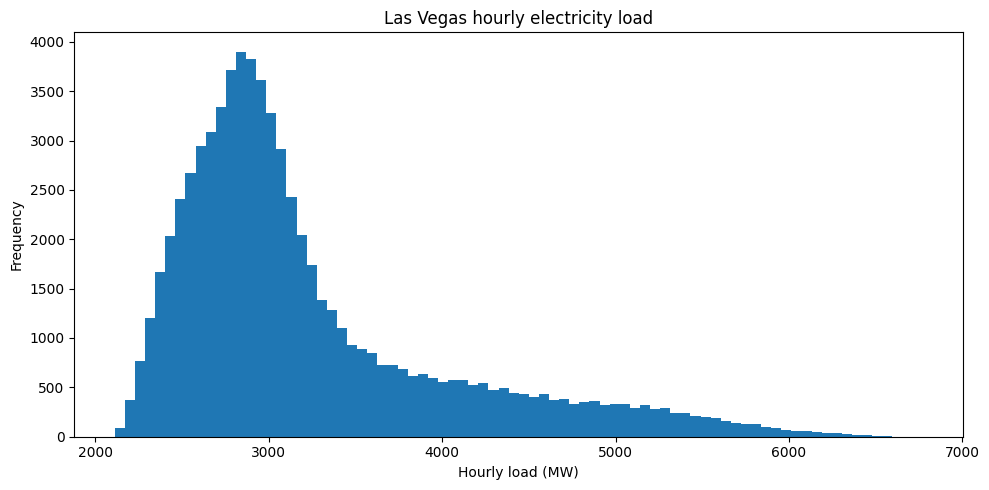

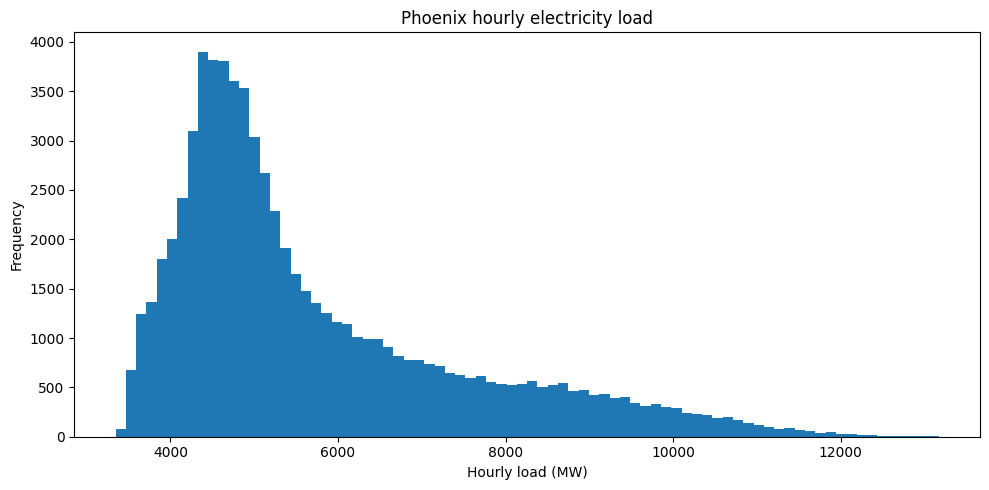

In [11]:
# 6.2 Visualize load distributions

for city, df in imputed.items():
    plt.figure(figsize=(10, 5))
    plt.hist(df["hourly_load_mw"].dropna(), bins=80)
    plt.title(f"{city} hourly electricity load")
    plt.xlabel("Hourly load (MW)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 7. Feature engineering

In [12]:
# 7.1 Feature engineering

def add_features(df):
    out = df.copy().sort_values("timestamp").reset_index(drop=True)
    ts = out["timestamp"]

    # Calendar
    out["hour"] = ts.dt.hour.astype(np.int8)
    out["day_of_week"] = ts.dt.dayofweek.astype(np.int8)
    out["month"] = ts.dt.month.astype(np.int8)
    out["day_of_year"] = ts.dt.dayofyear.astype(np.int16)
    out["is_weekend"] = (ts.dt.dayofweek >= 5).astype(np.int8)

    season_map = {
        12: "winter", 1: "winter", 2: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "autumn", 10: "autumn", 11: "autumn",
    }

    out["season"] = ts.dt.month.map(season_map)

    season_code = {
        "winter": 0,
        "spring": 1,
        "summer": 2,
        "autumn": 3,
    }

    out["season_code"] = (
        out["season"]
        .map(season_code)
        .astype(np.int8)
    )

    # Cyclical calendar features
    out["sin_hour"] = np.sin(
        2 * np.pi * out["hour"] / 24
    )
    out["cos_hour"] = np.cos(
        2 * np.pi * out["hour"] / 24
    )

    out["sin_dow"] = np.sin(
        2 * np.pi * out["day_of_week"] / 7
    )
    out["cos_dow"] = np.cos(
        2 * np.pi * out["day_of_week"] / 7
    )

    out["sin_month"] = np.sin(
        2 * np.pi * (out["month"] - 1) / 12
    )
    out["cos_month"] = np.cos(
        2 * np.pi * (out["month"] - 1) / 12
    )

    # Use 365-day periodicity because Feb 29 is intentionally removed.
    out["sin_doy"] = np.sin(
        2 * np.pi * (out["day_of_year"] - 1) / 365
    )
    out["cos_doy"] = np.cos(
        2 * np.pi * (out["day_of_year"] - 1) / 365
    )

    # Nonlinear weather terms
    BASE_TEMP_C = 18.3

    out["temperature_squared"] = (
        out["temperature_c"] ** 2
    )

    out["temperature_humidity_interaction"] = (
        out["temperature_c"] *
        out["relative_humidity_percent"]
    )

    out["cooling_degree_hour"] = np.maximum(
        out["temperature_c"] - BASE_TEMP_C,
        0
    )

    out["heating_degree_hour"] = np.maximum(
        BASE_TEMP_C - out["temperature_c"],
        0
    )

    return out

featured = {
    city: add_features(df)
    for city, df in imputed.items()
}

for city, df in featured.items():
    print(city, df.shape)


Las Vegas (70080, 37)
Phoenix (70080, 37)


## 8. Final common model feature list

The LSTM receives weather and calendar/context features.

The target is no longer absolute energy. The deviation target is created later, **after the chronological split**, so the baseline can be fitted only on training data and leakage is avoided.


In [55]:
MODEL_FEATURES = [
    "temperature_c",
    "dew_point_c",
    "precipitable_water_mm",
    "station_pressure_kpa",
    "wind_speed_ms",
    "wind_direction_deg",
    "broadband_aerosol_optical_depth",
]

print("MODEL_FEATURES updated:")
for i, feature in enumerate(MODEL_FEATURES, 1):
    print(f"{i}. {feature}")

print("\nNumber of features:", len(MODEL_FEATURES))

MODEL_FEATURES updated:
1. temperature_c
2. dew_point_c
3. precipitable_water_mm
4. station_pressure_kpa
5. wind_speed_ms
6. wind_direction_deg
7. broadband_aerosol_optical_depth

Number of features: 7


In [56]:
# 8.2 Check feature missingness before scaling

for city, df in featured.items():
    print(f"\n{city}")

    missing = df[MODEL_FEATURES].isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing):
        print(missing.to_string())
    else:
        print("No missing model features.")



Las Vegas
No missing model features.

Phoenix
No missing model features.


## 9. Chronological train / validation / test split

The split remains chronological:

* 70% training
* 15% validation
* 15% test

The city baseline is fitted using the **training split only**.


In [57]:
# 9.1 Split each city chronologically

def chronological_split(df, train_frac=0.70, val_frac=0.15):
    n = len(df)

    train_end = int(n * train_frac)
    val_end = train_end + int(n * val_frac)

    return (
        df.iloc[:train_end].copy(),
        df.iloc[train_end:val_end].copy(),
        df.iloc[val_end:].copy(),
    )

splits = {}

for city, df in featured.items():
    train, val, test = chronological_split(df)

    splits[city] = {
        "train": train,
        "val": val,
        "test": test,
    }

    print(f"\n{city}")

    for name, part in splits[city].items():
        print(
            f"{name:5s}: {len(part):6d} rows | "
            f"{part['timestamp'].min()} -> {part['timestamp'].max()}"
        )



Las Vegas
train:  49056 rows | 2016-01-01 00:00:00 -> 2021-08-07 23:00:00
val  :  10512 rows | 2021-08-08 00:00:00 -> 2022-10-19 23:00:00
test :  10512 rows | 2022-10-20 00:00:00 -> 2023-12-31 23:00:00

Phoenix
train:  49056 rows | 2016-01-01 00:00:00 -> 2021-08-07 23:00:00
val  :  10512 rows | 2021-08-08 00:00:00 -> 2022-10-19 23:00:00
test :  10512 rows | 2022-10-20 00:00:00 -> 2023-12-31 23:00:00


## 10. City specific baseline and weather driven deviation

### Baseline definition

For each city, the baseline represents expected electricity demand under normal conditions for the same:

* hour of day
* day of week
* season

The baseline lookup is fitted only on that city's training data.

For example:

`Monday + 14:00 + summer` gets a different baseline from `Sunday + 03:00 + winter`.

The deviation target is:

\[
D_t = E_t - B_t
\]

where `E_t` is actual energy and `B_t` is the city specific baseline.

For validation and test rows, the baseline is **never refitted** using those rows. If a combination is missing from training, the code falls back to a less specific training-only baseline and finally to the overall training mean.


In [58]:
# 10.1 Fit city-specific baselines using training data only

BASELINE_KEYS = [
    "hour",
    "day_of_week",
    "season_code",
]

def fit_city_baseline(train_df):
    train = train_df.copy()

    # Most specific baseline: hour + day of week + season
    baseline_hds = (
        train
        .groupby(BASELINE_KEYS, observed=True)["hourly_load_mw"]
        .mean()
    )

    # Fallback 1: hour + season
    baseline_hs = (
        train
        .groupby(["hour", "season_code"], observed=True)["hourly_load_mw"]
        .mean()
    )

    # Fallback 2: hour
    baseline_h = (
        train
        .groupby(["hour"], observed=True)["hourly_load_mw"]
        .mean()
    )

    # Final fallback
    global_baseline = float(
        train["hourly_load_mw"].mean()
    )

    return {
        "hour_day_season": baseline_hds,
        "hour_season": baseline_hs,
        "hour": baseline_h,
        "global": global_baseline,
    }


def apply_city_baseline(df, baseline):
    out = df.copy().reset_index(drop=True)

    hds_index = pd.MultiIndex.from_frame(
        out[BASELINE_KEYS]
    )

    out["energy_baseline"] = (
        baseline["hour_day_season"]
        .reindex(hds_index)
        .to_numpy()
    )

    # Fill missing specific combinations with hour + season
    missing = out["energy_baseline"].isna()

    if missing.any():
        hs_index = pd.MultiIndex.from_frame(
            out.loc[missing, ["hour", "season_code"]]
        )

        out.loc[missing, "energy_baseline"] = (
            baseline["hour_season"]
            .reindex(hs_index)
            .to_numpy()
        )

    # Fill remaining gaps with hour baseline
    missing = out["energy_baseline"].isna()

    if missing.any():
        out.loc[missing, "energy_baseline"] = (
            out.loc[missing, "hour"]
            .map(baseline["hour"])
            .to_numpy()
        )

    # Final fallback to training global mean
    out["energy_baseline"] = (
        out["energy_baseline"]
        .fillna(baseline["global"])
    )

    out["energy_deviation"] = (
        out["hourly_load_mw"] -
        out["energy_baseline"]
    )

    return out


baselines = {}
baseline_splits = {}

for city, city_splits in splits.items():

    baselines[city] = fit_city_baseline(
        city_splits["train"]
    )

    baseline_splits[city] = {}

    for split_name, split_df in city_splits.items():
        baseline_splits[city][split_name] = (
            apply_city_baseline(
                split_df,
                baselines[city]
            )
        )

    print(f"{city}")
    print(
        "Training global baseline:",
        round(baselines[city]["global"], 4)
    )

    for split_name, df in baseline_splits[city].items():
        print(
            f"{split_name:5s}: "
            f"mean energy={df['hourly_load_mw'].mean():.3f}, "
            f"mean baseline={df['energy_baseline'].mean():.3f}, "
            f"mean deviation={df['energy_deviation'].mean():.3f}"
        )

        assert np.isfinite(
            df["energy_baseline"].to_numpy()
        ).all()

        assert np.isfinite(
            df["energy_deviation"].to_numpy()
        ).all()


Las Vegas
Training global baseline: 3182.3403
train: mean energy=3182.340, mean baseline=3182.340, mean deviation=-0.000
val  : mean energy=3450.434, mean baseline=3214.195, mean deviation=236.239
test : mean energy=3273.855, mean baseline=3141.030, mean deviation=132.824
Phoenix
Training global baseline: 5606.6992
train: mean energy=5606.699, mean baseline=5606.699, mean deviation=-0.000
val  : mean energy=6130.096, mean baseline=5684.909, mean deviation=445.187
test : mean energy=5978.673, mean baseline=5512.942, mean deviation=465.731


In [59]:
# 10.2 Baseline diagnostics

for city, parts in baseline_splits.items():

    train_dev_mean = parts["train"]["energy_deviation"].mean()
    train_dev_std = parts["train"]["energy_deviation"].std()

    print(f"{city}")
    print(
        "Training deviation mean:",
        round(train_dev_mean, 6)
    )
    print(
        "Training deviation std:",
        round(train_dev_std, 6)
    )

    print(
        "Training baseline MAE:",
        round(
            np.abs(
                parts["train"]["hourly_load_mw"] -
                parts["train"]["energy_baseline"]
            ).mean(),
            4
        )
    )


Las Vegas
Training deviation mean: -0.0
Training deviation std: 371.322337
Training baseline MAE: 256.8612
Phoenix
Training deviation mean: -0.0
Training deviation std: 842.290762
Training baseline MAE: 606.3009


## 11. Leakage-safe scaling

The input scaler is fitted only on the source city's training features.

The target scaler is fitted only on the source city's **training energy deviation**, not on absolute energy.

This means the LSTM learns standardized weather driven deviations.


In [60]:
# 10.1 Source-city scalers

def fit_source_scalers(train_df):
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train = train_df[MODEL_FEATURES].astype(np.float32)
    y_train = train_df[[TARGET]].astype(np.float32)

    x_scaler.fit(X_train)
    y_scaler.fit(y_train)

    return x_scaler, y_scaler

scalers = {}

for city in splits:
    scalers[city] = {}

    scalers[city]["X"], scalers[city]["y"] = (
        fit_source_scalers(baseline_splits[city]["train"])
    )

    print(
        city,
        "X scaler fitted on",
        len(splits[city]["train"]),
        "training rows"
    )


Las Vegas X scaler fitted on 49056 training rows
Phoenix X scaler fitted on 49056 training rows


In [61]:
# 11.2 Apply source-city scalers to a split

def transform_with_source_scalers(
    df,
    x_scaler,
    y_scaler
):
    keep_cols = [
        "timestamp",
        "hourly_load_mw",
        "energy_baseline",
        "energy_deviation",
    ]

    out = df[keep_cols + MODEL_FEATURES].copy()

    out[MODEL_FEATURES] = (
        x_scaler
        .transform(
            out[MODEL_FEATURES].astype(np.float32)
        )
        .astype(np.float32)
    )

    out["energy_deviation"] = (
        y_scaler
        .transform(
            out[["energy_deviation"]].astype(np.float32)
        )
        .astype(np.float32)
        .ravel()
    )

    return out


scaled = {}

for city in baseline_splits:
    scaled[city] = {}

    for split_name, df in baseline_splits[city].items():
        scaled[city][split_name] = (
            transform_with_source_scalers(
                df,
                scalers[city]["X"],
                scalers[city]["y"]
            )
        )

    print(city, "scaled.")


Las Vegas scaled.
Phoenix scaled.


## 12. Cross-city transformations

For cross-city prediction:

1. The source city supplies the trained feature scaler and deviation target scaler.
2. The target city keeps its **own city-specific baseline**.
3. Target weather features are transformed using the source feature scaler.
4. The target deviation is transformed using the source deviation scaler only for evaluation/diagnostics.
5. Final absolute predictions are reconstructed using the **target city's own baseline**:

`final_prediction = target_baseline + predicted_deviation`


In [62]:
# 12.1 Prepare complete target-city data using source-city scaling

cross_city = {}

for source_city, target_city in [
    ("Las Vegas", "Phoenix"),
    ("Phoenix", "Las Vegas"),
]:
    source_x = scalers[source_city]["X"]
    source_y = scalers[source_city]["y"]

    target_df = baseline_splits[target_city]["test"].copy()

    transformed = transform_with_source_scalers(
        target_df,
        source_x,
        source_y
    )

    transformed["source_city"] = source_city
    transformed["target_city"] = target_city

    cross_city[
        f"{source_city}_to_{target_city}"
    ] = transformed

    print(
        f"{source_city} -> {target_city}:",
        transformed.shape
    )


Las Vegas -> Phoenix: (10512, 13)
Phoenix -> Las Vegas: (10512, 13)


In [63]:
# 12.2 Final prediction reconstruction helper

def reconstruct_final_energy(
    baseline,
    predicted_deviation
):
    return (
        np.asarray(baseline, dtype=np.float64) +
        np.asarray(predicted_deviation, dtype=np.float64)
    )


# Example of the intended final calculation:
#
# final_predicted_energy = reconstruct_final_energy(
#     target_baseline,
#     predicted_deviation
# )
#
# This is the quantity that must be compared against actual test energy.


In [64]:
# 13.1 VIF Analysis

from statsmodels.stats.outliers_influence import variance_inflation_factor

VIF_FEATURES = MODEL_FEATURES.copy()

for city, df in featured.items():

    print("\n" + "=" * 70)
    print(f"VIF ANALYSIS: {city}")
    print("=" * 70)

    X_vif = df[VIF_FEATURES].copy()

    # Remove rows with missing or infinite values
    X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

    vif_results = []

    for i, feature in enumerate(X_vif.columns):

        vif_value = variance_inflation_factor(
            X_vif.values,
            i
        )

        vif_results.append({
            "feature": feature,
            "VIF": vif_value
        })

    vif_df = (
        pd.DataFrame(vif_results)
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

    print(vif_df.to_string(index=False))

    print("\nInterpretation:")

    for _, row in vif_df.iterrows():

        vif = row["VIF"]

        if vif < 5:
            level = "Low"
        elif vif < 10:
            level = "Moderate/High"
        else:
            level = "Very High"

        print(
            f"{row['feature']:30s} "
            f"VIF = {vif:8.3f}   {level}"
        )

    # Save for later comparison
    if "vif_reports" not in globals():
        vif_reports = {}

    vif_reports[city] = vif_df


VIF ANALYSIS: Las Vegas
                        feature      VIF
          precipitable_water_mm 2.712121
                    dew_point_c 2.676004
                  temperature_c 1.774306
           station_pressure_kpa 1.597114
                  wind_speed_ms 1.289294
broadband_aerosol_optical_depth 1.117328
             wind_direction_deg 1.083685

Interpretation:
precipitable_water_mm          VIF =    2.712   Low
dew_point_c                    VIF =    2.676   Low
temperature_c                  VIF =    1.774   Low
station_pressure_kpa           VIF =    1.597   Low
wind_speed_ms                  VIF =    1.289   Low
broadband_aerosol_optical_depth VIF =    1.117   Low
wind_direction_deg             VIF =    1.084   Low

VIF ANALYSIS: Phoenix
                        feature       VIF
                    dew_point_c 16.037182
          precipitable_water_mm 15.616561
                  temperature_c  1.826995
           station_pressure_kpa  1.668466
             wind_direction_deg 

In [65]:
# 13.2 Pearson Correlation Analysis

pearson_reports = {}

for city, split_data in baseline_splits.items():

    # Use the training data only for feature analysis
    df = split_data["train"].copy()

    analysis_df = df[
        MODEL_FEATURES + [
            "hourly_load_mw",
            "energy_deviation"
        ]
    ].copy()

    analysis_df = (
        analysis_df
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    corr = analysis_df.corr(method="pearson")

    target_corr = corr[
        ["hourly_load_mw", "energy_deviation"]
    ].drop(
        ["hourly_load_mw", "energy_deviation"],
        errors="ignore"
    )

    target_corr = target_corr.sort_values(
        "energy_deviation",
        key=lambda x: x.abs(),
        ascending=False
    )

    pearson_reports[city] = target_corr

    print("\n" + "=" * 70)
    print(f"PEARSON CORRELATION: {city}")
    print("=" * 70)

    print(
        target_corr.to_string()
    )


PEARSON CORRELATION: Las Vegas
                                 hourly_load_mw  energy_deviation
temperature_c                          0.373216          0.194474
precipitable_water_mm                  0.426785          0.145947
dew_point_c                            0.346510          0.137042
station_pressure_kpa                  -0.240395         -0.058033
broadband_aerosol_optical_depth        0.141218         -0.056379
wind_direction_deg                     0.081801         -0.021690
wind_speed_ms                          0.008895          0.005566

PEARSON CORRELATION: Phoenix
                                 hourly_load_mw  energy_deviation
temperature_c                          0.454099          0.226897
precipitable_water_mm                  0.477289          0.203265
dew_point_c                            0.460455          0.201023
station_pressure_kpa                  -0.365749         -0.122915
wind_speed_ms                          0.011063          0.040162
broadband_aero

In [66]:
# 13.3 Spearman Correlation Analysis

spearman_reports = {}

for city, split_data in baseline_splits.items():

    # Use training data only
    df = split_data["train"].copy()

    analysis_df = df[
        MODEL_FEATURES + [
            "hourly_load_mw",
            "energy_deviation"
        ]
    ].copy()

    analysis_df = (
        analysis_df
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    corr = analysis_df.corr(method="spearman")

    target_corr = corr[
        ["hourly_load_mw", "energy_deviation"]
    ].drop(
        ["hourly_load_mw", "energy_deviation"],
        errors="ignore"
    )

    target_corr = target_corr.sort_values(
        "energy_deviation",
        key=lambda x: x.abs(),
        ascending=False
    )

    spearman_reports[city] = target_corr

    print("\n" + "=" * 70)
    print(f"SPEARMAN CORRELATION: {city}")
    print("=" * 70)

    print(
        target_corr.to_string()
    )


SPEARMAN CORRELATION: Las Vegas
                                 hourly_load_mw  energy_deviation
temperature_c                          0.336071          0.198797
precipitable_water_mm                  0.397675          0.134795
dew_point_c                            0.315737          0.127097
broadband_aerosol_optical_depth        0.175068         -0.080114
station_pressure_kpa                  -0.243041         -0.051988
wind_direction_deg                     0.089404         -0.038990
wind_speed_ms                          0.074268          0.013377

SPEARMAN CORRELATION: Phoenix
                                 hourly_load_mw  energy_deviation
temperature_c                          0.461951          0.222575
dew_point_c                            0.432658          0.199499
precipitable_water_mm                  0.426242          0.197341
station_pressure_kpa                  -0.395586         -0.109775
wind_speed_ms                          0.016399          0.057327
broadband_ae

In [67]:
# 13.4 Nonlinear Feature Engineering Candidates

def add_candidate_features(df):

    out = df.copy()

    # Temperature nonlinearities
    if "Temp" in out.columns:
        out["Temp_squared"] = out["Temp"] ** 2
        out["Temp_cubed"] = out["Temp"] ** 3

    # Dew point / temperature relationship
    if "Temp" in out.columns and "Dew Point" in out.columns:
        out["Temp_DewPoint_diff"] = (
            out["Temp"] - out["Dew Point"]
        )

    # Temperature-humidity interaction
    if "Temp" in out.columns and "RH" in out.columns:
        out["Temp_RH_interaction"] = (
            out["Temp"] * out["RH"]
        )

    # Wind nonlinearity
    if "Wind Speed" in out.columns:
        out["WindSpeed_squared"] = (
            out["Wind Speed"] ** 2
        )

    # Cooling degree style feature
    # Base temperature = 18 C
    if "Temp" in out.columns:
        out["Cooling_Degree"] = (
            out["Temp"] - 18
        ).clip(lower=0)

        out["Heating_Degree"] = (
            18 - out["Temp"]
        ).clip(lower=0)

    return out


candidate_features = {}

for city, df in featured.items():

    candidate_features[city] = add_candidate_features(df)

    print("\n" + "=" * 70)
    print(f"NEW CANDIDATE FEATURES: {city}")
    print("=" * 70)

    original = set(df.columns)
    new_features = [
        c for c in candidate_features[city].columns
        if c not in original
    ]

    for feature in new_features:
        print(feature)


NEW CANDIDATE FEATURES: Las Vegas

NEW CANDIDATE FEATURES: Phoenix


In [68]:
# 13.5 Mutual Information With Energy Deviation

from sklearn.feature_selection import mutual_info_regression

mi_reports = {}

CANDIDATE_FEATURES = [
    "Temp_squared",
    "Temp_cubed",
    "Temp_DewPoint_diff",
    "Temp_RH_interaction",
    "WindSpeed_squared",
    "Cooling_Degree",
    "Heating_Degree"
]

for city, split_data in baseline_splits.items():

    # IMPORTANT:
    # Use training data only because energy_deviation
    # exists here and we must avoid test-data leakage.
    train_df = split_data["train"].copy()

    # Create nonlinear candidate features on the training data
    train_df = add_candidate_features(train_df)

    candidate_cols = [
        c for c in MODEL_FEATURES + CANDIDATE_FEATURES
        if c in train_df.columns
    ]

    analysis_df = train_df[
        candidate_cols + ["energy_deviation"]
    ].copy()

    analysis_df = (
        analysis_df
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    X = analysis_df[candidate_cols]
    y = analysis_df["energy_deviation"]

    mi_values = mutual_info_regression(
        X,
        y,
        random_state=42
    )

    mi_df = pd.DataFrame({
        "feature": candidate_cols,
        "mutual_information": mi_values
    })

    mi_df = (
        mi_df
        .sort_values(
            "mutual_information",
            ascending=False
        )
        .reset_index(drop=True)
    )

    mi_reports[city] = mi_df

    print("\n" + "=" * 70)
    print(f"MUTUAL INFORMATION: {city}")
    print("=" * 70)

    print(
        mi_df.to_string(index=False)
    )


MUTUAL INFORMATION: Las Vegas
                        feature  mutual_information
broadband_aerosol_optical_depth            0.233468
                  temperature_c            0.111058
          precipitable_water_mm            0.079983
           station_pressure_kpa            0.067975
                    dew_point_c            0.039354
             wind_direction_deg            0.025195
                  wind_speed_ms            0.019479

MUTUAL INFORMATION: Phoenix
                        feature  mutual_information
broadband_aerosol_optical_depth            0.245319
                  temperature_c            0.098056
           station_pressure_kpa            0.050468
                    dew_point_c            0.049120
          precipitable_water_mm            0.046008
             wind_direction_deg            0.008645
                  wind_speed_ms            0.007301


In [69]:
# 13.6 Random Forest Feature Importance

from sklearn.ensemble import RandomForestRegressor

rf_reports = {}

for city, df in candidate_features.items():

    candidate_cols = [
        c for c in df.columns
        if c in MODEL_FEATURES
        or c in [
            "Temp_squared",
            "Temp_cubed",
            "Temp_DewPoint_diff",
            "Temp_RH_interaction",
            "WindSpeed_squared",
            "Cooling_Degree",
            "Heating_Degree"
        ]
    ]

    train_df = baseline_splits[city]["train"].copy()

    # Add the same candidate features to training data
    train_df = add_candidate_features(train_df)

    train_df = (
        train_df[
            candidate_cols + ["energy_deviation"]
        ]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    X = train_df[candidate_cols]
    y = train_df["energy_deviation"]

    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X, y)

    importance_df = pd.DataFrame({
        "feature": candidate_cols,
        "importance": rf.feature_importances_
    })

    importance_df = (
        importance_df
        .sort_values(
            "importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    rf_reports[city] = importance_df

    print("\n" + "=" * 70)
    print(f"RANDOM FOREST FEATURE IMPORTANCE: {city}")
    print("=" * 70)

    print(
        importance_df.to_string(index=False)
    )


RANDOM FOREST FEATURE IMPORTANCE: Las Vegas
                        feature  importance
broadband_aerosol_optical_depth    0.373698
                  temperature_c    0.177678
          precipitable_water_mm    0.149892
                    dew_point_c    0.107612
           station_pressure_kpa    0.101350
             wind_direction_deg    0.048743
                  wind_speed_ms    0.041027

RANDOM FOREST FEATURE IMPORTANCE: Phoenix
                        feature  importance
broadband_aerosol_optical_depth    0.409757
                  temperature_c    0.223605
                    dew_point_c    0.120946
           station_pressure_kpa    0.099737
             wind_direction_deg    0.054313
          precipitable_water_mm    0.050665
                  wind_speed_ms    0.040976


In [70]:
# 13.7 Combined Feature Engineering Report

combined_reports = {}

for city in featured.keys():

    vif_df = vif_reports[city].copy()

    pearson_df = pearson_reports[city].reset_index()
    pearson_df = pearson_df.rename(
        columns={
            "index": "feature"
        }
    )

    spearman_df = spearman_reports[city].reset_index()
    spearman_df = spearman_df.rename(
        columns={
            "index": "feature"
        }
    )

    mi_df = mi_reports[city].copy()
    rf_df = rf_reports[city].copy()

    report = vif_df.merge(
        pearson_df[
            ["feature", "energy_deviation"]
        ].rename(
            columns={
                "energy_deviation":
                "pearson_deviation"
            }
        ),
        on="feature",
        how="outer"
    )

    report = report.merge(
        spearman_df[
            ["feature", "energy_deviation"]
        ].rename(
            columns={
                "energy_deviation":
                "spearman_deviation"
            }
        ),
        on="feature",
        how="outer"
    )

    report = report.merge(
        mi_df,
        on="feature",
        how="outer"
    )

    report = report.merge(
        rf_df,
        on="feature",
        how="outer"
    )

    # Absolute correlations for easier ranking
    report["abs_pearson"] = (
        report["pearson_deviation"].abs()
    )

    report["abs_spearman"] = (
        report["spearman_deviation"].abs()
    )

    report = report.sort_values(
        [
            "mutual_information",
            "importance"
        ],
        ascending=False
    ).reset_index(drop=True)

    combined_reports[city] = report

    print("\n" + "=" * 90)
    print(f"COMBINED FEATURE ENGINEERING REPORT: {city}")
    print("=" * 90)

    print(
        report.to_string(index=False)
    )


COMBINED FEATURE ENGINEERING REPORT: Las Vegas
                        feature      VIF  pearson_deviation  spearman_deviation  mutual_information  importance  abs_pearson  abs_spearman
broadband_aerosol_optical_depth 1.117328          -0.056379           -0.080114            0.233468    0.373698     0.056379      0.080114
                  temperature_c 1.774306           0.194474            0.198797            0.111058    0.177678     0.194474      0.198797
          precipitable_water_mm 2.712121           0.145947            0.134795            0.079983    0.149892     0.145947      0.134795
           station_pressure_kpa 1.597114          -0.058033           -0.051988            0.067975    0.101350     0.058033      0.051988
                    dew_point_c 2.676004           0.137042            0.127097            0.039354    0.107612     0.137042      0.127097
             wind_direction_deg 1.083685          -0.021690           -0.038990            0.025195    0.048743     0.

In [71]:
# 13.8 Preliminary Feature Recommendation

print("=" * 80)
print("PRELIMINARY FEATURE SCREENING")
print("=" * 80)

for city in vif_reports.keys():

    print("\n" + "=" * 80)
    print(f"FEATURE SCREENING: {city}")
    print("=" * 80)

    # Get the individual reports
    vif_df = vif_reports[city].copy()
    pearson_df = pearson_reports[city].reset_index()
    spearman_df = spearman_reports[city].reset_index()
    mi_df = mi_reports[city].copy()
    rf_df = rf_reports[city].copy()

    # Rename correlation columns
    pearson_df = pearson_df.rename(
        columns={
            "index": "feature",
            "energy_deviation": "pearson_deviation"
        }
    )

    spearman_df = spearman_df.rename(
        columns={
            "index": "feature",
            "energy_deviation": "spearman_deviation"
        }
    )

    # Start with VIF
    report = vif_df.copy()

    # Add Pearson
    report = report.merge(
        pearson_df[
            ["feature", "pearson_deviation"]
        ],
        on="feature",
        how="outer"
    )

    # Add Spearman
    report = report.merge(
        spearman_df[
            ["feature", "spearman_deviation"]
        ],
        on="feature",
        how="outer"
    )

    # Add Mutual Information
    report = report.merge(
        mi_df[
            ["feature", "mutual_information"]
        ],
        on="feature",
        how="outer"
    )

    # Add Random Forest importance
    report = report.merge(
        rf_df[
            ["feature", "importance"]
        ],
        on="feature",
        how="outer"
    )

    # Absolute correlation values
    report["abs_pearson"] = (
        report["pearson_deviation"].abs()
    )

    report["abs_spearman"] = (
        report["spearman_deviation"].abs()
    )

    # Preliminary recommendation
    recommendations = []

    for _, row in report.iterrows():

        feature = row["feature"]
        vif = row["VIF"]
        pearson = row["abs_pearson"]
        spearman = row["abs_spearman"]
        mi = row["mutual_information"]
        importance = row["importance"]

        reasons = []

        if pd.notna(mi) and mi > 0.05:
            reasons.append("nonlinear signal")

        if pd.notna(importance) and importance > 0.01:
            reasons.append("RF signal")

        if pd.notna(spearman) and spearman > 0.10:
            reasons.append("relationship with deviation")

        if pd.notna(vif) and vif >= 10:
            reasons.append("high multicollinearity")

        if pd.notna(vif) and vif < 10 and (
            (pd.notna(mi) and mi > 0.05) or
            (pd.notna(importance) and importance > 0.01) or
            (pd.notna(spearman) and spearman > 0.10)
        ):
            recommendation = "KEEP / INVESTIGATE"

        elif pd.notna(vif) and vif >= 10:
            recommendation = "INVESTIGATE COLLINEARITY"

        else:
            recommendation = "REVIEW"

        recommendations.append({
            "feature": feature,
            "VIF": vif,
            "Pearson": pearson,
            "Spearman": spearman,
            "Mutual_Information": mi,
            "RF_Importance": importance,
            "Recommendation": recommendation,
            "Reasons": ", ".join(reasons)
        })

    final_report = (
        pd.DataFrame(recommendations)
        .sort_values(
            [
                "Mutual_Information",
                "RF_Importance"
            ],
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        final_report.to_string(index=False)
    )

    # Store it
    if "combined_reports" not in globals():
        combined_reports = {}

    combined_reports[city] = final_report

PRELIMINARY FEATURE SCREENING

FEATURE SCREENING: Las Vegas
                        feature      VIF  Pearson  Spearman  Mutual_Information  RF_Importance     Recommendation                                                  Reasons
broadband_aerosol_optical_depth 1.117328 0.056379  0.080114            0.233468       0.373698 KEEP / INVESTIGATE                              nonlinear signal, RF signal
                  temperature_c 1.774306 0.194474  0.198797            0.111058       0.177678 KEEP / INVESTIGATE nonlinear signal, RF signal, relationship with deviation
          precipitable_water_mm 2.712121 0.145947  0.134795            0.079983       0.149892 KEEP / INVESTIGATE nonlinear signal, RF signal, relationship with deviation
           station_pressure_kpa 1.597114 0.058033  0.051988            0.067975       0.101350 KEEP / INVESTIGATE                              nonlinear signal, RF signal
                    dew_point_c 2.676004 0.137042  0.127097            0.039354      

In [72]:
print("FINAL MODEL FEATURES")
print("=" * 50)

for feature in MODEL_FEATURES:
    print(feature)

print("\nNumber of features:", len(MODEL_FEATURES))

FINAL MODEL FEATURES
temperature_c
dew_point_c
precipitable_water_mm
station_pressure_kpa
wind_speed_ms
wind_direction_deg
broadband_aerosol_optical_depth

Number of features: 7


In [73]:
print("MODEL_FEATURES is currently:")
print(MODEL_FEATURES)
print("\nNumber of features:", len(MODEL_FEATURES))

MODEL_FEATURES is currently:
['temperature_c', 'dew_point_c', 'precipitable_water_mm', 'station_pressure_kpa', 'wind_speed_ms', 'wind_direction_deg', 'broadband_aerosol_optical_depth']

Number of features: 7


In [74]:
print("\nChecking both cities:")

for city, df in featured.items():

    missing = [
        feature
        for feature in MODEL_FEATURES
        if feature not in df.columns
    ]

    if missing:
        print(f"{city}: MISSING -> {missing}")
    else:
        print(f"{city}: ALL 7 FEATURES PRESENT")
        


Checking both cities:
Las Vegas: ALL 7 FEATURES PRESENT
Phoenix: ALL 7 FEATURES PRESENT


## 13. Sequence generation

The sequence input remains 24 hours.

The sequence target is now the **deviation at the final hour of the sequence**.

The original sequence construction logic is retained.


In [77]:
# 12.1 NumPy sequence builder for sanity checks

def make_sequences_numpy(df, sequence_length=24):
    X = df[MODEL_FEATURES].to_numpy(dtype=np.float32)
    y = df[TARGET].to_numpy(dtype=np.float32)

    n = len(df) - sequence_length + 1

    if n <= 0:
        raise ValueError(
            f"Need at least {sequence_length} rows."
        )

    X_seq = np.empty(
        (n, sequence_length, len(MODEL_FEATURES)),
        dtype=np.float32
    )

    y_seq = np.empty(
        n,
        dtype=np.float32
    )

    for i in range(n):
        end = i + sequence_length
        X_seq[i] = X[i:end]
        y_seq[i] = y[end - 1]

    return X_seq, y_seq

for city in scaled:
    X_check, y_check = make_sequences_numpy(
        scaled[city]["train"].head(200),
        SEQUENCE_LENGTH
    )

    print(
        city,
        "X:", X_check.shape,
        "y:", y_check.shape
    )


Las Vegas X: (177, 24, 7) y: (177,)
Phoenix X: (177, 24, 7) y: (177,)


In [78]:
# 12.2 TensorFlow / GPU validation

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))

# Optional memory growth on detected GPUs.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


TensorFlow: 2.10.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [81]:
# 12.3 Memory-efficient tf.data sequence pipeline

def make_tf_dataset(
    df,
    batch_size=64,
    sequence_length=24,
    shuffle=False
):
    X = df[MODEL_FEATURES].to_numpy(dtype=np.float32)
    y = df[TARGET].to_numpy(dtype=np.float32)

    # Any remaining missing value means the affected sequence should not
    # be used. Because missingness is already diagnosed above, fail loudly.
    if not np.isfinite(X).all():
        raise ValueError(
            "Feature matrix contains NaN/Inf. "
            "Inspect missing_reports before training."
        )

    if not np.isfinite(y).all():
        raise ValueError(
            "Target contains NaN/Inf."
        )

    ds = tf.data.Dataset.from_tensor_slices((X, y))

    ds = ds.window(
        size=sequence_length,
        shift=1,
        stride=1,
        drop_remainder=True
    )

    ds = ds.flat_map(
        lambda x, y: tf.data.Dataset.zip((
            x.batch(sequence_length, drop_remainder=True),
            y.batch(sequence_length, drop_remainder=True)
        ))
    )

    ds = ds.map(
        lambda x, y: (x, y[-1]),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(df), 10000),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

# Construct local datasets only after the GPU environment has been validated.
tf_datasets = {}

for city in scaled:
    tf_datasets[city] = {
        "train": make_tf_dataset(
            scaled[city]["train"],
            shuffle=True
        ),
        "val": make_tf_dataset(
            scaled[city]["val"],
            shuffle=False
        ),
        "test": make_tf_dataset(
            scaled[city]["test"],
            shuffle=False
        ),
    }

    print(
        city,
        "train batches:",
        tf.data.experimental.cardinality(
            tf_datasets[city]["train"]
        ).numpy()
    )


Las Vegas train batches: -2
Phoenix train batches: -2


In [75]:
print("=" * 60)
print("SEQUENCE PIPELINE CHECK")
print("=" * 60)

print("TARGET:")
print(TARGET)

print("\nMODEL FEATURES:")
for i, feature in enumerate(MODEL_FEATURES, 1):
    print(f"{i}. {feature}")

print("\nNumber of features:", len(MODEL_FEATURES))

print("\nChecking scaled datasets:")

for city in scaled:

    df = scaled[city]["train"]

    print(f"\n{city}")
    print("Rows:", len(df))
    print("energy_deviation present:", "energy_deviation" in df.columns)
    print("hourly_load_mw present:", "hourly_load_mw" in df.columns)

    missing_features = [
        f for f in MODEL_FEATURES
        if f not in df.columns
    ]

    print("Missing model features:", missing_features)

SEQUENCE PIPELINE CHECK
TARGET:
energy_deviation

MODEL FEATURES:
1. temperature_c
2. dew_point_c
3. precipitable_water_mm
4. station_pressure_kpa
5. wind_speed_ms
6. wind_direction_deg
7. broadband_aerosol_optical_depth

Number of features: 7

Checking scaled datasets:

Las Vegas
Rows: 49056
energy_deviation present: True
hourly_load_mw present: True
Missing model features: []

Phoenix
Rows: 49056
energy_deviation present: True
hourly_load_mw present: True
Missing model features: []


In [82]:
print("=" * 70)
print("TF.DATA SEQUENCE VALIDATION")
print("=" * 70)

for city in tf_datasets:

    print(f"\n{city}")

    train_ds = tf_datasets[city]["train"]

    for X_batch, y_batch in train_ds.take(1):

        print("X batch shape:", X_batch.shape)
        print("y batch shape:", y_batch.shape)

        print("X dtype:", X_batch.dtype)
        print("y dtype:", y_batch.dtype)

        print("X finite:", bool(tf.reduce_all(tf.math.is_finite(X_batch))))
        print("y finite:", bool(tf.reduce_all(tf.math.is_finite(y_batch))))

        print("Expected X dimensions:")
        print("batch × 24 × 7")

        print("Actual:", X_batch.shape)

        print("Expected y dimensions:")
        print("batch")

        print("Actual:", y_batch.shape)

TF.DATA SEQUENCE VALIDATION

Las Vegas
X batch shape: (64, 24, 7)
y batch shape: (64,)
X dtype: <dtype: 'float32'>
y dtype: <dtype: 'float32'>
X finite: True
y finite: True
Expected X dimensions:
batch × 24 × 7
Actual: (64, 24, 7)
Expected y dimensions:
batch
Actual: (64,)

Phoenix
X batch shape: (64, 24, 7)
y batch shape: (64,)
X dtype: <dtype: 'float32'>
y dtype: <dtype: 'float32'>
X finite: True
y finite: True
Expected X dimensions:
batch × 24 × 7
Actual: (64, 24, 7)
Expected y dimensions:
batch
Actual: (64,)


In [83]:
for city in tf_datasets:

    print("\n", city)

    X_batch, y_batch = next(
        iter(tf_datasets[city]["train"])
    )

    print("First target values:")
    print(y_batch[:10].numpy())

    print("Target range:")
    print(
        float(tf.reduce_min(y_batch)),
        "to",
        float(tf.reduce_max(y_batch))
    )


 Las Vegas
First target values:
[-0.7380589   0.11174948 -1.394015   -0.61262184  0.13483775  0.35787544
 -0.45358768 -0.65610147 -0.71265715 -0.13920198]
Target range:
-2.4659667015075684 to 1.0114312171936035

 Phoenix
First target values:
[-0.47407177 -0.00968556 -0.16556089 -0.5671771  -0.16666318 -0.5559349
 -0.31904793 -0.48747557 -0.05224113  0.370323  ]
Target range:
-2.086127281188965 to 1.4484646320343018


In [80]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.10.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 14. Save reproducible preprocessing artifacts

The saved artifacts now include:

* city-specific baseline tables
* featured data
* chronological train/validation/test splits
* deviation target
* feature scaler
* deviation target scaler
* cross-city test data
* missing weather reports
* preprocessing metadata

The original notebook is not modified.


In [84]:
# 14.1 Save outputs

def city_key(city):
    return city.lower().replace(" ", "_")


for city, df in featured.items():

    key = city_key(city)
    city_dir = OUTPUT_DIR / key
    city_dir.mkdir(parents=True, exist_ok=True)

    # Full feature-engineered data
    df.to_csv(
        city_dir / f"{key}_featured.csv",
        index=False
    )

    # Original splits
    for split_name, split_df in splits[city].items():
        split_df.to_csv(
            city_dir / f"{key}_{split_name}_raw_target.csv",
            index=False
        )

    # Baseline + deviation splits
    for split_name, split_df in baseline_splits[city].items():
        split_df.to_csv(
            city_dir / f"{key}_{split_name}_baseline_deviation.csv",
            index=False
        )

    # Scalers
    with open(
        city_dir / "feature_scaler.pkl",
        "wb"
    ) as f:
        pickle.dump(
            scalers[city]["X"],
            f
        )

    with open(
        city_dir / "deviation_target_scaler.pkl",
        "wb"
    ) as f:
        pickle.dump(
            scalers[city]["y"],
            f
        )

    # Baseline tables
    with open(
        city_dir / "city_baseline.pkl",
        "wb"
    ) as f:
        pickle.dump(
            baselines[city],
            f
        )

    missing_reports[city].to_csv(
        city_dir / f"{key}_missing_weather_report.csv"
    )

    metadata = {
        "city": city,
        "absolute_energy_column": "hourly_load_mw",
        "baseline_column": "energy_baseline",
        "model_target": "energy_deviation",
        "deviation_definition": "hourly_load_mw - energy_baseline",
        "final_prediction_definition": "energy_baseline + predicted_deviation",
        "baseline_keys": BASELINE_KEYS,
        "baseline_fit_on": "city training split only",
        "feature_scaler_fit_on": "city training split only",
        "target_scaler_fit_on": "city training deviation only",
        "model_features": MODEL_FEATURES,
        "sequence_length": SEQUENCE_LENGTH,
        "train_fraction": 0.70,
        "validation_fraction": 0.15,
        "test_fraction": 0.15,
        "feb29_removed": True,
        "max_weather_interpolation_gap_hours": MAX_WEATHER_GAP_HOURS,
        "target_interpolation": False,
        "fixed_energy_outlier_threshold": None,
        "target_derived_features": False,
    }

    with open(
        city_dir / "preprocessing_metadata.json",
        "w"
    ) as f:
        json.dump(
            metadata,
            f,
            indent=2
        )


cross_dir = OUTPUT_DIR / "cross_city"
cross_dir.mkdir(
    parents=True,
    exist_ok=True
)

for experiment, df in cross_city.items():

    key = experiment.lower().replace(
        " ",
        "_"
    )

    df.to_csv(
        cross_dir / f"{key}_test.csv",
        index=False
    )


print(
    "Saved preprocessing outputs to:"
)
print(
    OUTPUT_DIR.resolve()
)


Saved preprocessing outputs to:
D:\Downloads\BTP\model_training\lstm_training_3\processed_lstm_baseline_deviation


# 15. Final validation

The final validation checks:

1. February 29 is absent.
2. Timestamps are unique.
3. Energy is valid.
4. Model features are complete and finite.
5. The corrected continuity logic reports no unexpected gaps.
6. Baselines are finite.
7. Deviations are finite.
8. The baseline for every validation/test row comes from training-derived lookup tables.
9. The final reconstruction identity holds:

`actual_energy = baseline + deviation`

up to floating point precision.


In [86]:
# 15.1 Final automated validation

for city, df in featured.items():

    ts = (
        df["timestamp"]
        .sort_values()
        .reset_index(drop=True)
    )

    feb29_count = (
        (ts.dt.month == 2) &
        (ts.dt.day == 29)
    ).sum()

    assert feb29_count == 0, (
        f"{city}: found {feb29_count} February 29 rows"
    )

    assert ts.duplicated().sum() == 0, (
        f"{city}: duplicate timestamps found"
    )

    assert df["hourly_load_mw"].notna().all(), (
        f"{city}: target contains missing values"
    )

    assert np.isfinite(
        df["hourly_load_mw"].to_numpy()
    ).all(), (
        f"{city}: target contains non-finite values"
    )

    assert (
        df["hourly_load_mw"] >= 0
    ).all(), (
        f"{city}: negative energy values found"
    )

    assert all(
        c in df.columns
        for c in MODEL_FEATURES
    ), (
        f"{city}: feature mismatch"
    )

    assert df[MODEL_FEATURES].notna().all().all(), (
        f"{city}: missing model features remain"
    )

    assert np.isfinite(
        df[MODEL_FEATURES].to_numpy(dtype=np.float64)
    ).all(), (
        f"{city}: non-finite model features remain"
    )

    report, _, _, _ = continuity_report(df)

    assert report["unexpected_transitions"] == 0, (
        f"{city}: unexpected timestamp gap detected"
    )

    for split_name, split_df in baseline_splits[city].items():

        assert split_df["energy_baseline"].notna().all()
        assert split_df["energy_deviation"].notna().all()

        reconstructed = (
            split_df["energy_baseline"] +
            split_df["energy_deviation"]
        )

        max_error = np.max(
            np.abs(
                reconstructed.to_numpy() -
                split_df["hourly_load_mw"].to_numpy()
            )
        )

        assert max_error < 1e-8, (
            f"{city} {split_name}: "
            f"baseline + deviation reconstruction failed"
        )

    print(
        f"{city}: PASS | "
        f"rows={len(df)} | "
        f"Feb29={feb29_count} | "
        f"unexpected gaps={report['unexpected_transitions']}"
    )

print("ALL FINAL VALIDATION CHECKS PASSED.")


Las Vegas: PASS | rows=70080 | Feb29=0 | unexpected gaps=0
Phoenix: PASS | rows=70080 | Feb29=0 | unexpected gaps=0
ALL FINAL VALIDATION CHECKS PASSED.


# 16. Cross-city experiment summary

The preprocessing is now ready for LSTM training.

### Local-city experiment

For each city:

`city weather + calendar → LSTM → predicted deviation`

Then:

`city baseline + predicted deviation → final predicted energy`

### Cross-city experiment

For `Las Vegas → Phoenix`:

`Las Vegas trained LSTM → Phoenix weather → predicted Phoenix deviation`

Then:

`Phoenix baseline + predicted deviation → final Phoenix prediction`

The reverse experiment is identical:

`Phoenix trained LSTM → Las Vegas weather → predicted Las Vegas deviation`

This design deliberately allows each city to retain its own structural energy baseline while testing whether the **weather driven response** learned in one city transfers to the other.
